In Scope — اللي هنعمله
- تحليل الركاب الأطفال باستخدام العمر.
- حساب أعداد الناجين وغير الناجين ونسب النجاة.
- استكشاف العلاقة بين النجاة وبيانات الأسرة المتاحة.
- توضيح البيانات الناقصة وحدود الاستنتاجات.


Out of Scope — اللي مش هنعمله حاليًا
- إثبات إن وجود الوالدين تسبب في النجاة.
- تحديد الهوية الحقيقية لكل أب أو أم اعتمادًا على أعداد أفراد الأسرة فقط.
- بناء موديل تنبؤ أو Dashboard قبل إنهاء التحليل الأساسي.

In [6]:
path_to_zip_file="/content/titanic.zip"
directory_to_extract_to='/content/sample_data/Untitled Folder'
import zipfile
with zipfile.ZipFile(path_to_zip_file, 'r') as zip_ref:
    zip_ref.extractall(directory_to_extract_to)


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [8]:
df=pd.read_csv('/content/sample_data/Untitled Folder/gender_submission.csv')

In [9]:
df

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
...,...,...
413,1305,0
414,1306,1
415,1307,0
416,1308,0


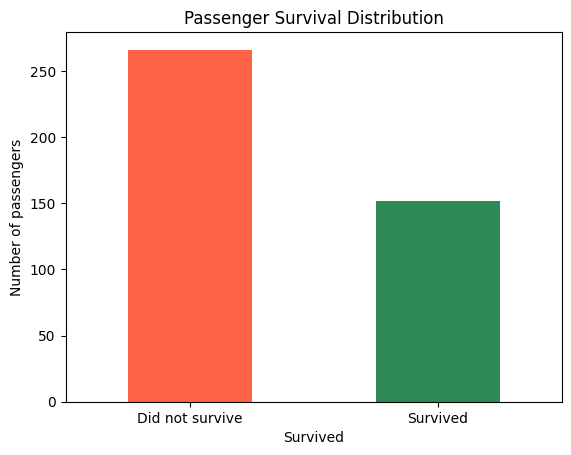

In [13]:
import matplotlib.pyplot as plt

df['Survived'].value_counts().sort_index().plot(
    kind='bar',
    color=['tomato', 'seagreen']
)

plt.xticks([0, 1], ['Did not survive', 'Survived'], rotation=0)
plt.ylabel('Number of passengers')
plt.title('Passenger Survival Distribution')
plt.show()

In [31]:
data=pd.read_csv("/content/sample_data/Untitled Folder/train.csv")

In [32]:
data

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [33]:
print(data.isna().sum())


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [34]:
data.count()

,0
PassengerId,891
Survived,891
Pclass,891
Name,891
Sex,891
Age,714
SibSp,891
Parch,891
Ticket,891
Fare,891


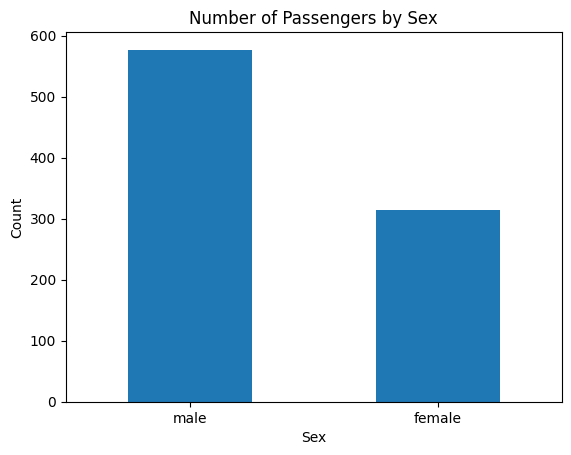

In [35]:
data['Sex'].value_counts().plot(kind='bar')

plt.title('Number of Passengers by Sex')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

In [36]:
children = data[data['Age'] < 16]
children


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.00,3,1,349909,21.0750,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.00,1,0,237736,30.0708,NaN,C
10,11,1,3,"Sandstrom, Miss. Marguerite Rut",female,4.00,1,1,PP 9549,16.7000,G6,S
14,15,0,3,"Vestrom, Miss. Hulda Amanda Adolfina",female,14.00,0,0,350406,7.8542,NaN,S
16,17,0,3,"Rice, Master. Eugene",male,2.00,4,1,382652,29.1250,NaN,Q
...,...,...,...,...,...,...,...,...,...,...,...,...
831,832,1,2,"Richards, Master. George Sibley",male,0.83,1,1,29106,18.7500,NaN,S
850,851,0,3,"Andersson, Master. Sigvard Harald Elias",male,4.00,4,2,347082,31.2750,NaN,S
852,853,0,3,"Boulos, Miss. Nourelain",female,9.00,1,1,2678,15.2458,NaN,C
869,870,1,3,"Johnson, Master. Harold Theodor",male,4.00,1,1,347742,11.1333,NaN,S


In [38]:
# Since 'data' is now the training set (train.csv), it already contains the 'Survived' column.
# No merge with 'df' is needed.

# Filter for children under 16 from the training set
children = data[data['Age'] < 16]

# Calculate the survival rate
survival_rate = children['Survived'].mean()

print("Number of children under 16 in the training set:", len(children))
print("Survival rate:", round(survival_rate * 100, 2), "%")

Number of children under 16 in the training set: 83
Survival rate: 59.04 %


In [39]:
print(data.shape)
print(data.columns.tolist())

(891, 12)
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [41]:
adults = data[
    (data['Age'] >= 16) &
    (data['Age'].notna())
]

print("Number of adults:", len(adults))

print(
    "Adult survival rate:",
    round(adults['Survived'].mean() * 100, 2),
    "%"
)

Number of adults: 631
Adult survival rate: 38.19 %


In [42]:
children = data.loc[
    data['Age'].notna() & (data['Age'] < 16)
].copy()

children['FamilySize'] = (
    children['SibSp'] + children['Parch'] + 1
)

print(children['FamilySize'].value_counts().sort_index())

FamilySize
1     6
2    13
3    24
4    12
5     4
6    12
7     8
8     4
Name: count, dtype: int64


In [43]:
survival_by_family = (
    children.groupby('FamilySize')['Survived']
    .agg(['count', 'sum', 'mean'])
    .reset_index()
)

survival_by_family.columns = [
    'FamilySize',
    'ChildrenCount',
    'SurvivedCount',
    'SurvivalRate'
]

survival_by_family['SurvivalRate'] = (
    survival_by_family['SurvivalRate'] * 100
).round(2)

print(survival_by_family)

   FamilySize  ChildrenCount  SurvivedCount  SurvivalRate
0           1              6              4         66.67
1           2             13             11         84.62
2           3             24             21         87.50
3           4             12             11         91.67
4           5              4              0          0.00
5           6             12              0          0.00
6           7              8              2         25.00
7           8              4              0          0.00


In [44]:
survival_by_family_class = (
    children.groupby(['Pclass', 'FamilySize'])['Survived']
    .agg(
        ChildrenCount='count',
        SurvivedCount='sum',
        SurvivalRate='mean'
    )
    .reset_index()
)

survival_by_family_class['SurvivalRate'] = (
    survival_by_family_class['SurvivalRate'] * 100
).round(2)

print(survival_by_family_class.to_string(index=False))

 Pclass  FamilySize  ChildrenCount  SurvivedCount  SurvivalRate
      1           2              1              1        100.00
      1           3              1              1        100.00
      1           4              4              3         75.00
      2           2              3              3        100.00
      2           3             12             12        100.00
      2           4              4              4        100.00
      3           1              6              4         66.67
      3           2              9              7         77.78
      3           3             11              8         72.73
      3           4              4              4        100.00
      3           5              4              0          0.00
      3           6             12              0          0.00
      3           7              8              2         25.00
      3           8              4              0          0.00


 Pclass    Sex  ChildrenCount  SurvivedCount  SurvivalRate
      1 female              3              2         66.67
      1   male              3              3        100.00
      2 female             10             10        100.00
      2   male              9              9        100.00
      3 female             30             16         53.33
      3   male             28              9         32.14


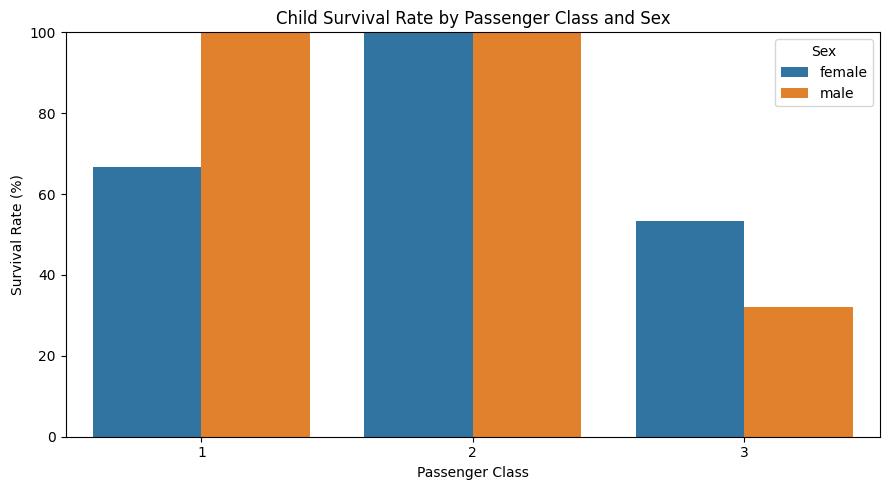

In [46]:
import seaborn as sns

survival_by_sex_class = (
    children.groupby(['Pclass', 'Sex'], observed=True)['Survived']
    .agg(['count', 'sum', 'mean'])
    .reset_index()
)

survival_by_sex_class.columns = [
    'Pclass', 'Sex', 'ChildrenCount',
    'SurvivedCount', 'SurvivalRate'
]

survival_by_sex_class['SurvivalRate'] *= 100

print(survival_by_sex_class.round(2).to_string(index=False))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=survival_by_sex_class,
    x='Pclass',
    y='SurvivalRate',
    hue='Sex'
)

plt.title('Child Survival Rate by Passenger Class and Sex')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate (%)')
plt.ylim(0, 100)
plt.legend(title='Sex')
plt.tight_layout()
plt.show()

In [47]:
test = pd.read_csv("/content/sample_data/Untitled Folder/test.csv")

In [48]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    object 
 3   Sex          418 non-null    object 
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    object 
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     object 
 10  Embarked     418 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 36.1+ KB


In [50]:
gender_submission = pd.read_csv("/content/sample_data/Untitled Folder/gender_submission.csv")
print(gender_submission.head())
print(gender_submission.shape)

   PassengerId  Survived
0          892         0
1          893         1
2          894         0
3          895         0
4          896         1
(418, 2)


In [52]:
children_ml = data.loc[
    data["Age"].notna() &
    (data["Age"] < 16)
].copy()

children_ml["FamilySize"] = (
    children_ml["SibSp"] +
    children_ml["Parch"] + 1
)

print("Total children:", len(children_ml))

print("\nSurvival counts:")
print(children_ml["Survived"].value_counts())

print("\nSurvival rate:")
print(children_ml["Survived"].mean())

Total children: 83

Survival counts:
Survived
1    49
0    34
Name: count, dtype: int64

Survival rate:
0.5903614457831325


In [53]:
from sklearn.model_selection import train_test_split

features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "FamilySize"
]

X = children_ml[features]
y = children_ml["Survived"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nValidation target distribution:")
print(y_val.value_counts())

Training examples: 66
Validation examples: 17

Training target distribution:
Survived
1    39
0    27
Name: count, dtype: int64

Validation target distribution:
Survived
1    10
0     7
Name: count, dtype: int64


In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize"
]

categorical_features = [
    "Sex",
    "Embarked"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [55]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Baseline model
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

# Logistic Regression model
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

# Predictions on validation data
baseline_preds = baseline_model.predict(X_val)
logistic_preds = logistic_model.predict(X_val)

# Evaluation
for name, predictions in [
    ("Baseline", baseline_preds),
    ("Logistic Regression", logistic_preds)
]:
    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y_val, predictions), 3))
    print("Precision:", round(precision_score(y_val, predictions, zero_division=0), 3))
    print("Recall:", round(recall_score(y_val, predictions, zero_division=0), 3))
    print("F1-score:", round(f1_score(y_val, predictions, zero_division=0), 3))
    print("Confusion Matrix:\n", confusion_matrix(y_val, predictions))


Baseline
Accuracy: 0.588
Precision: 0.588
Recall: 1.0
F1-score: 0.741
Confusion Matrix:
 [[ 0  7]
 [ 0 10]]

Logistic Regression
Accuracy: 0.706
Precision: 0.778
Recall: 0.7
F1-score: 0.737
Confusion Matrix:
 [[5 2]
 [3 7]]


In [56]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=3,
        random_state=42
    ))
])

random_forest_model.fit(X_train, y_train)

rf_preds = random_forest_model.predict(X_val)

print("Random Forest")
print("Accuracy:", round(accuracy_score(y_val, rf_preds), 3))
print("Precision:", round(precision_score(y_val, rf_preds, zero_division=0), 3))
print("Recall:", round(recall_score(y_val, rf_preds, zero_division=0), 3))
print("F1-score:", round(f1_score(y_val, rf_preds, zero_division=0), 3))
print("Confusion Matrix:\n", confusion_matrix(y_val, rf_preds))

Random Forest
Accuracy: 0.824
Precision: 0.818
Recall: 0.9
F1-score: 0.857
Confusion Matrix:
 [[5 2]
 [1 9]]


Stratified Cross-Validation

In [59]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "precision", "recall", "f1"]
    )

    cv_results.append({
        "Model": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Precision Mean": scores["test_precision"].mean(),
        "Recall Mean": scores["test_recall"].mean(),
        "F1 Mean": scores["test_f1"].mean()
    })

cv_results_df = pd.DataFrame(cv_results).round(3)
cv_results_df

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Recall Mean,F1 Mean
0,Logistic Regression,0.848,0.084,0.871,0.900,0.879
1,Random Forest,0.895,0.091,0.876,0.975,0.920


In [61]:
test_children = test.loc[
    test["Age"].notna() &
    (test["Age"] < 16)
].copy()

test_children["FamilySize"] = (
    test_children["SibSp"] +
    test_children["Parch"] + 1
)

print("Total passengers in test:", len(test))
print("Children with known age:", len(test_children))

test_children[["PassengerId", "Age", "Sex", "Pclass", "FamilySize"]].head()

Total passengers in test: 418
Children with known age: 32


,PassengerId,Age,Sex,Pclass,FamilySize
5,897,14.0,male,3,1
21,913,9.0,male,3,2
55,947,10.0,male,3,6
64,956,13.0,male,1,5
80,972,6.0,male,3,3


In [62]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=3,
        random_state=42
    ))
])

final_model.fit(X, y)

print("Final model trained on:", len(X), "children")

Final model trained on: 83 children


In [63]:
# Predict survival for children in the test set
test_features = test_children[features]

child_predictions = final_model.predict(test_features)

# Create a predictions DataFrame
child_submission = pd.DataFrame({
    "PassengerId": test_children["PassengerId"].values,
    "Survived": child_predictions
})

print("Predictions created:", len(child_submission))
print("\nPredicted survival counts:")
print(child_submission["Survived"].value_counts().sort_index())

child_submission.head(10)

Predictions created: 32

Predicted survival counts:
Survived
0     6
1    26
Name: count, dtype: int64


,PassengerId,Survived
0,897,1
1,913,1
2,947,0
3,956,1
4,972,1
5,981,1
6,1009,1
7,1012,1
8,1032,0
9,1046,0


In [64]:
child_submission.to_csv(
    "titanic_children_predictions.csv",
    index=False
)

print("File saved successfully!")

File saved successfully!


In [65]:

rf_classifier = final_model.named_steps["classifier"]

feature_names = final_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

importance_df

,Feature,Importance
0,numeric__FamilySize,0.319988
1,numeric__SibSp,0.317773
2,numeric__Pclass,0.116679
3,numeric__Fare,0.111835
4,numeric__Age,0.069031
5,numeric__Parch,0.015032
6,categorical__Embarked_C,0.011720
7,categorical__Embarked_S,0.010937
8,categorical__Sex_male,0.009812
9,categorical__Sex_female,0.009604


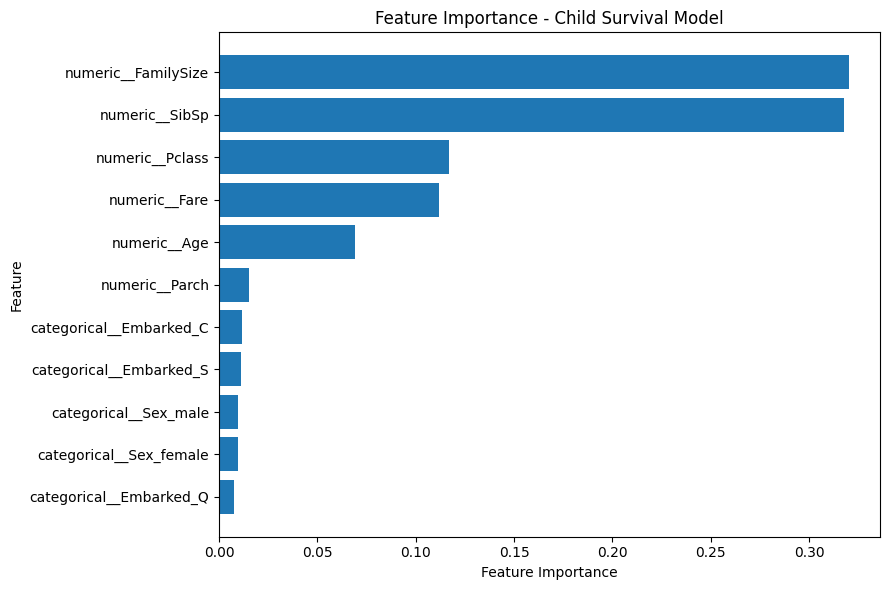

In [66]:
import matplotlib.pyplot as plt

plot_df = importance_df.sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    plot_df["Feature"],
    plot_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - Child Survival Model")
plt.tight_layout()
plt.show()

try wo family size to show how does it help

In [67]:
features_without_family = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

X_without_family = children_ml[features_without_family]

In [71]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Define numeric features excluding 'FamilySize'
numeric_features_no_family = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

categorical_features = [
    "Sex",
    "Embarked"
]

# 2. Re-create preprocessor for features without family size
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_no_family = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features_no_family),
    ("categorical", categorical_pipeline, categorical_features)
])

# 3. Create a fresh model pipeline
model_no_family = Pipeline([
    ("preprocessor", preprocessor_no_family),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=3,
        random_state=42
    ))
])

# 4. Use the same train/validation split
X_train_no_family = X_train[features_without_family]
X_val_no_family = X_val[features_without_family]

# 5. Fit and evaluate the model
model_no_family.fit(X_train_no_family, y_train)
predictions_no_family = model_no_family.predict(X_val_no_family)

print("Accuracy:", round(accuracy_score(y_val, predictions_no_family), 3))
print("Precision:", round(precision_score(y_val, predictions_no_family, zero_division=0), 3))
print("Recall:", round(recall_score(y_val, predictions_no_family, zero_division=0), 3))
print("F1-score:", round(f1_score(y_val, predictions_no_family, zero_division=0), 3))

Accuracy: 0.824
Precision: 0.818
Recall: 0.9
F1-score: 0.857


In [72]:
comparison = pd.DataFrame({
    "Actual": y_val,
    "With_FamilySize": random_forest_model.predict(X_val),
    "Without_FamilySize": predictions_no_family
})

comparison["Same_Prediction"] = (
    comparison["With_FamilySize"] ==
    comparison["Without_FamilySize"]
)

print("Matching predictions:",
      comparison["Same_Prediction"].sum(), "out of", len(comparison))

print("\nDifferent predictions:")
display(comparison[~comparison["Same_Prediction"]])

Matching predictions: 17 out of 17

Different predictions:


,Actual,With_FamilySize,Without_FamilySize,Same_Prediction
